# Topic modelling with LDA

Download the small Canvas archive and unpack it before running the notebook from top to bottom. If your kernel is missing packages, install them with:

`%pip install "gensim>=4" "pyLDAvis>=3" nltk pandas seaborn`

In [1]:
import sys
print("Python:", sys.version.split()[0])

Python: 3.12.16


In [2]:
from pathlib import Path
import random
from string import punctuation

import gensim
from gensim import corpora, models
from nltk.tokenize import TreebankWordTokenizer
import pandas as pd
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
import seaborn as sns

In [3]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/annekroon/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [4]:
print(f"Your gensim version is {gensim.__version__}. This notebook assumes that you have version 4.0 or higher. If not, please upgrade.")
assert int(gensim.__version__[0])>=4

print(f"Your pyLDAvis version is {pyLDAvis.__version__}. This notebook assumes that you have version 3.0 or higher. If not, please upgrade.")
assert int(pyLDAvis.__version__[0])>=3

Your gensim version is 4.4.0. This notebook assumes that you have version 4.0 or higher. If not, please upgrade.
Your pyLDAvis version is 3.4.0. This notebook assumes that you have version 3.0 or higher. If not, please upgrade.


LDA is probabilistic. Each model uses the same explicit random seed so you can rerun its cell and compare settings.

In [5]:
SEED = 2022
N_TOPICS = 10

# Working with textual data

### 0. Get the data.

- Download `articles.zip` from Canvas (under `Modules -- Week 5`). Please note that this is not the full dataset, but random sample of the data described [here](https://dx.doi.org/10.7910/DVN/ULHLCB).


<div class="alert-danger">
<p>Alternatively, you can also download <code>articles.tar.gz</code> from
<a href="https://dx.doi.org/10.7910/DVN/ULHLCB">https://dx.doi.org/10.7910/DVN/ULHLCB</a> to get <strong>all</strong> the data. Please note that this is a very large dataset, and for practice purposes, you do not need everything. </p>
</div>



- Unpack it. 


### 1. Inspect the structure of the dataset.
What information do the following elements give you?

- folder (directory) names
- folder structure/hierarchy
- file names
- file contents

### 2. Discuss strategies for working with this dataset!

- Which questions could you answer?
- How could you deal with it, given the size and the structure?

### 3. Read some (or all?) data

Here is some example code that you can modify. you could, for instance, do the following to read a *part* of your dataset.

In [6]:
# Unpack the Canvas archive so the articles folder is next to this notebook.
PATH = Path("articles")

In [7]:
RANDOM_N = 2000

# Read up to RANDOM_N distinct articles from each outlet.
def read_data(listofoutlets, RANDOM_N, PATH):
    rng = random.Random(SEED)
    dates, titles, texts, outlets = [], [], [], []
    for outlet in listofoutlets:
        files = sorted(file for file in PATH.glob(f"*/{outlet}/*") if file.is_file())
        if not files:
            raise FileNotFoundError(
                f"No files found for {outlet} under {PATH.resolve()}. "
                "Check that you unpacked the Canvas archive and set PATH to the articles folder."
            )
        for file in rng.sample(files, k=min(RANDOM_N, len(files))):
            date, title = file.name.rsplit("--", 2)[-2:]
            dates.append(date)
            titles.append(title)
            texts.append(file.read_text(encoding="utf-8"))
            outlets.append(outlet)
    return dates, titles, texts, outlets

dates, title, texts, outlets = read_data(["Infowars"], RANDOM_N, PATH)
print(f"Loaded {len(texts)} distinct articles.")

Loaded 2000 distinct articles.


In [8]:
len(texts)

2000

In [9]:
texts[0][:500]

'Facebook has a moral responsibility to delete Infowars from its platform according to CNNs Oliver Darcy and Brian Stelter.'

In [10]:
texts_clean = [text.lower() for text in texts]
texts_clean=[" ".join(text.split()) for text in texts_clean]  #remove dubble spaces
texts_clean = ["".join([l for l in text if l not in punctuation]) for text in texts_clean] #remove punctuaction
texts_clean[0][:500]

'facebook has a moral responsibility to delete infowars from its platform according to cnns oliver darcy and brian stelter'

## manually removing stopwords

In [11]:
mystopwords = set(stopwords.words('english')) # use default NLTK stopword list; alternatively:
# mystopwords = set(open('mystopwordfile.txt').readlines())  #read stopword list from a textfile with one stopword per line

texts_clean = [" ".join(word for word in text.split() if word not in mystopwords) for text in texts_clean]
texts_clean[0][:500]

'facebook moral responsibility delete infowars platform according cnns oliver darcy brian stelter'

## Tokenize texts

In [12]:
tokenized_texts_clean = [TreebankWordTokenizer().tokenize(text) for text in texts_clean ] # tokenize texts; convert all strings to a list of tokens
tokenized_texts_clean[0][:500]

['facebook',
 'moral',
 'responsibility',
 'delete',
 'infowars',
 'platform',
 'according',
 'cnns',
 'oliver',
 'darcy',
 'brian',
 'stelter']

## Fit standard LDA on word counts

Each article becomes a list of word IDs and their counts. Set the number of topics before fitting. We use this count-based model for the visualisation and the time plot.

In [13]:
id2word_m1 = corpora.Dictionary(tokenized_texts_clean)
ldacorpus_m1 = [id2word_m1.doc2bow(text) for text in tokenized_texts_clean]

# The stability check reuses these settings and changes only the seed.
lda_settings = {"id2word": id2word_m1, "num_topics": N_TOPICS}
lda_m1 = models.LdaModel(ldacorpus_m1, random_state=SEED, **lda_settings)
lda_m1.print_topics()

[(0,
  '0.012*"said" + 0.011*"trump" + 0.006*"president" + 0.006*"people" + 0.004*"would" + 0.004*"also" + 0.004*"one" + 0.003*"us" + 0.003*"paul" + 0.003*"house"'),
 (1,
  '0.011*"trump" + 0.006*"president" + 0.006*"said" + 0.005*"fbi" + 0.004*"media" + 0.004*"one" + 0.004*"news" + 0.003*"political" + 0.003*"also" + 0.003*"would"'),
 (2,
  '0.014*"trump" + 0.006*"said" + 0.005*"people" + 0.005*"president" + 0.004*"also" + 0.004*"new" + 0.003*"us" + 0.003*"would" + 0.003*"house" + 0.003*"state"'),
 (3,
  '0.011*"said" + 0.008*"trump" + 0.005*"president" + 0.004*"would" + 0.004*"people" + 0.004*"fbi" + 0.004*"democrats" + 0.003*"percent" + 0.003*"news" + 0.003*"house"'),
 (4,
  '0.007*"trump" + 0.007*"said" + 0.005*"president" + 0.004*"people" + 0.004*"one" + 0.003*"us" + 0.003*"also" + 0.003*"news" + 0.003*"new" + 0.003*"would"'),
 (5,
  '0.008*"trump" + 0.006*"said" + 0.006*"people" + 0.005*"president" + 0.004*"news" + 0.004*"one" + 0.003*"would" + 0.003*"media" + 0.003*"going" + 0.00

### Optional experiment: TF–IDF weighting

Standard LDA models token counts. Here we keep the vocabulary fixed and try TF–IDF weights to see how the top words change. Use the count-based model for the remaining analysis.

In [14]:
tfidf_model = models.TfidfModel(ldacorpus_m1)
lda_m2 = models.LdaModel(
    tfidf_model[ldacorpus_m1],
    id2word=id2word_m1,
    num_topics=N_TOPICS,
    random_state=SEED,
)
lda_m2.print_topics(num_words=5)

[(0,
  '0.001*"trump" + 0.001*"infowars" + 0.001*"jones" + 0.001*"alex" + 0.001*"school"'),
 (1,
  '0.001*"trump" + 0.001*"said" + 0.001*"media" + 0.001*"kavanaugh" + 0.001*"democrats"'),
 (2,
  '0.001*"trump" + 0.001*"jones" + 0.001*"president" + 0.001*"said" + 0.001*"former"'),
 (3,
  '0.001*"trump" + 0.001*"fbi" + 0.001*"president" + 0.001*"percent" + 0.001*"border"'),
 (4,
  '0.001*"trump" + 0.001*"democrats" + 0.001*"clinton" + 0.001*"kavanaugh" + 0.001*"president"'),
 (5,
  '0.001*"trump" + 0.001*"percent" + 0.001*"president" + 0.001*"news" + 0.001*"said"'),
 (6,
  '0.001*"trump" + 0.001*"border" + 0.001*"president" + 0.001*"us" + 0.001*"people"'),
 (7,
  '0.001*"trump" + 0.001*"president" + 0.001*"infowars" + 0.001*"said" + 0.001*"democrats"'),
 (8,
  '0.001*"trump" + 0.001*"president" + 0.001*"white" + 0.001*"new" + 0.001*"border"'),
 (9,
  '0.001*"trump" + 0.001*"gun" + 0.001*"said" + 0.001*"people" + 0.001*"cnn"')]

### Optional experiment: add bigrams

Count single words and adjacent pairs of tokens. This model also filters very rare and very common terms, so any change may reflect the filtering as well as the added bigrams.

In [15]:
documents_bigrams = [
    ["_".join(pair) for pair in nltk.ngrams(tokens, 2)] for tokens in tokenized_texts_clean
]
documents_bigrams[0][:20]

['facebook_moral',
 'moral_responsibility',
 'responsibility_delete',
 'delete_infowars',
 'infowars_platform',
 'platform_according',
 'according_cnns',
 'cnns_oliver',
 'oliver_darcy',
 'darcy_brian',
 'brian_stelter']

In [16]:
documents_uniandbigrams = [
    words + bigrams for words, bigrams in zip(tokenized_texts_clean, documents_bigrams)
]
documents_uniandbigrams[0][:20]

['facebook',
 'moral',
 'responsibility',
 'delete',
 'infowars',
 'platform',
 'according',
 'cnns',
 'oliver',
 'darcy',
 'brian',
 'stelter',
 'facebook_moral',
 'moral_responsibility',
 'responsibility_delete',
 'delete_infowars',
 'infowars_platform',
 'platform_according',
 'according_cnns',
 'cnns_oliver']

In [17]:
id2word_m3 = corpora.Dictionary(documents_uniandbigrams)
id2word_m3.filter_extremes(no_below=5, no_above=0.5)
if not id2word_m3:
    raise ValueError("No terms survived filtering. Try a larger sample or relax filter_extremes.")

ldacorpus_m3 = [id2word_m3.doc2bow(text) for text in documents_uniandbigrams]
lda_m3 = models.LdaModel(
    ldacorpus_m3, id2word=id2word_m3, num_topics=N_TOPICS, random_state=SEED
)
lda_m3.print_topics(num_words=5)

[(0,
  '0.012*"trump" + 0.007*"president" + 0.006*"people" + 0.005*"one" + 0.004*"new"'),
 (1,
  '0.014*"trump" + 0.005*"president" + 0.004*"one" + 0.004*"also" + 0.004*"percent"'),
 (2,
  '0.010*"trump" + 0.008*"president" + 0.005*"media" + 0.004*"people" + 0.003*"new"'),
 (3,
  '0.009*"trump" + 0.006*"president" + 0.004*"news" + 0.004*"fbi" + 0.004*"people"'),
 (4,
  '0.008*"trump" + 0.004*"president" + 0.004*"also" + 0.004*"cnn" + 0.004*"like"'),
 (5,
  '0.009*"trump" + 0.004*"president" + 0.004*"people" + 0.004*"us" + 0.003*"media"'),
 (6,
  '0.007*"trump" + 0.005*"would" + 0.005*"president" + 0.004*"people" + 0.004*"us"'),
 (7,
  '0.012*"trump" + 0.007*"president" + 0.005*"people" + 0.005*"would" + 0.005*"house"'),
 (8,
  '0.008*"trump" + 0.007*"president" + 0.006*"people" + 0.004*"would" + 0.004*"one"'),
 (9,
  '0.008*"trump" + 0.005*"people" + 0.005*"president" + 0.005*"also" + 0.003*"white"')]

## Validate the count-based LDA model

Run the main count-based fit above, then work through these three checks. The numbered steps ask whether the top words go together, whether topics recur after a refit, and whether a label fits the original texts.

### 1. Coherence

**Question.** Do the leading words in each topic tend to appear together in the same articles?

Run the cell below for a mean score and a table for each topic. This uses Gensim's `u_mass` measure with the original count corpus as the reference. Higher values indicate stronger co-occurrence under this measure. Compare scores only when the measure, reference corpus, and number of top words are the same. A topic with a high score still needs to be read and interpreted. [Gensim coherence documentation](https://radimrehurek.com/gensim/models/coherencemodel.html)

In [18]:
lda_words_to_check = min(5, len(id2word_m1))
if lda_words_to_check < 2:
    raise ValueError("Coherence needs at least two words in the vocabulary.")

def top_lda_words(fitted_model):
    return [
        [word for word, _ in fitted_model.show_topic(topic_id, topn=lda_words_to_check)]
        for topic_id in range(fitted_model.num_topics)
    ]

lda_words_a = top_lda_words(lda_m1)
lda_coherence = models.CoherenceModel(
    topics=lda_words_a, corpus=ldacorpus_m1, dictionary=id2word_m1, coherence="u_mass"
)
lda_coherence_table = pd.DataFrame({
    "Topic": range(lda_m1.num_topics),
    "Top words": [", ".join(words) for words in lda_words_a],
    "Coherence (u_mass)": lda_coherence.get_coherence_per_topic(),
})
print(f"Mean coherence: {lda_coherence_table['Coherence (u_mass)'].mean():.3f}")
lda_coherence_table.round(3)

Mean coherence: -0.879


,Topic,Top words,Coherence (u_mass)
0,0,"said, trump, president, people, would",-0.813
1,1,"trump, president, said, fbi, media",-1.288
2,2,"trump, said, people, president, also",-0.777
3,3,"said, trump, president, would, people",-0.799
4,4,"trump, said, president, people, one",-0.803
5,5,"trump, said, people, president, news",-0.862
6,6,"trump, said, would, people, president",-0.731
7,7,"trump, president, people, said, media",-0.892
8,8,"trump, said, president, would, like",-0.910
9,9,"trump, said, people, us, one",-0.913


### 2. Stability across random seeds

**Question.** Do we recover similar topics when we fit LDA again?

Run the cell below. It keeps the articles, vocabulary, and model settings fixed and changes only the random seed. Topic IDs can change between runs, so the code pairs topics by their top words. Each topic is paired once to maximise the total overlap.

The overlap score is **shared words divided by the total number of distinct words in the pair**. A score of 1 means the top-word lists contain the same words. A score of 0 means they share none. The lowest-overlap pairs appear first. Look at the word lists for a strong and a weak match before deciding which themes recur.

In [19]:
from scipy.optimize import linear_sum_assignment

lda_second_seed = SEED + 1
lda_seed_check = models.LdaModel(
    ldacorpus_m1, random_state=lda_second_seed, **lda_settings
)
lda_words_b = top_lda_words(lda_seed_check)

first_sets = [set(words) for words in lda_words_a]
second_sets = [set(words) for words in lda_words_b]
overlap = [
    [len(first & second) / len(first | second) for second in second_sets]
    for first in first_sets
]
first_ids, second_ids = linear_sum_assignment(overlap, maximize=True)

lda_stability = pd.DataFrame([
    {
        f"Topic (seed {SEED})": first_id,
        f"Topic (seed {lda_second_seed})": second_id,
        "Top words, first run": ", ".join(lda_words_a[first_id]),
        "Top words, second run": ", ".join(lda_words_b[second_id]),
        "Top-word overlap": overlap[first_id][second_id],
    }
    for first_id, second_id in zip(first_ids, second_ids)
]).sort_values("Top-word overlap")

print(f"Mean top-word overlap: {lda_stability['Top-word overlap'].mean():.2f}")
lda_stability.round(2)

Mean top-word overlap: 0.74


,Topic (seed 2022),Topic (seed 2023),"Top words, first run","Top words, second run",Top-word overlap
1,1,0,"trump, president, said, fbi, media","said, would, trump, also, president",0.43
3,3,8,"said, trump, president, would, people","trump, president, said, would, new",0.67
5,5,7,"trump, said, people, president, news","trump, said, president, news, one",0.67
6,6,4,"trump, said, would, people, president","trump, said, president, would, house",0.67
7,7,6,"trump, president, people, said, media","people, trump, president, said, also",0.67
8,8,5,"trump, said, president, would, like","trump, said, president, us, would",0.67
9,9,3,"trump, said, people, us, one","trump, said, people, us, president",0.67
0,0,9,"said, trump, president, people, would","said, trump, president, people, would",1.00
2,2,2,"trump, said, people, president, also","trump, people, said, president, also",1.00
4,4,1,"trump, said, president, people, one","trump, said, president, one, people",1.00


### 3. Read the original articles

Pick a topic ID from the first run and change `topic_to_read` below. The cell shows the top words and excerpts from three articles with high shares of that topic. To read a full article, use `print(texts[article_id])` with the ID printed next to its title.

Write a possible label and point to a passage that supports it. For a fuller check, also read some randomly selected articles and look for passages that challenge the label. Report what the coherence and stability scores showed and what you learned from reading. [Maier et al. (2018)](https://doi.org/10.1080/19312458.2018.1430754)

In [20]:
topic_to_read = 0  # Use a topic ID from the coherence table.
print("Top words:", ", ".join(lda_words_a[topic_to_read]))

article_shares = pd.Series([
    dict(topic_mix).get(topic_to_read, 0.0)
    for topic_mix in lda_m1.get_document_topics(ldacorpus_m1, minimum_probability=0.0)
])
for article_id, share in article_shares.nlargest(3).items():
    print(f"\nArticle {article_id} | {share:.0%} estimated topic share")
    print(title[article_id])
    print(texts[article_id][:600])

Top words: said, trump, president, people, would

Article 1916 | 100% estimated topic share
Myth vs Fact DHS Zero-Tolerance Policy
In recent days, we have seen reporters, Members of Congress, and other groups mislead the public on the Department of Homeland Securitys (DHS) zero-tolerance policy.

Federal law enforcement officers have sworn duties to enforce the laws that Congress passes.  Repeating intentionally untrue and unsubstantiated statements about DHS agents, officers, and procedures is irresponsible and deeply disrespectful to the men and women who risk their lives every day to secure our border and enforce our laws.

DHS has a policy to separate families at the border.

DHS does not have a blanket policy of sepa

Article 1665 | 100% estimated topic share
Rand Paul Warns New US War Powers Act Will Rubber Stamp GLOBAL CONFLICT
Senator Rand Paul warned Tuesday that a new war powers act currently making its way through the Senate will expand the Presidents authority to declare wa

## Visualise the count-based model

Click a circle to inspect the words that distinguish a topic. The visual starts numbering at 1. The corresponding Gensim topic IDs start at 0.

In [23]:
vis_data = gensimvis.prepare(lda_m1, ldacorpus_m1, id2word_m1, sort_topics=False, mds='mmds')
pyLDAvis.display(vis_data)

/Users/annekroon/Documents/git-repos/teaching-bdaca/.venv-lda/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/Users/annekroon/Documents/git-repos/teaching-bdaca/.venv-lda/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


## Track topic shares over time

Estimate the topic mix of each article using the count-based model. Then take the mean article share for each topic within each year and month.

In [24]:
all_topics = lda_m1.get_document_topics(ldacorpus_m1, minimum_probability=0.0)
all_topics_csr = gensim.matutils.corpus2csc(all_topics, num_terms=lda_m1.num_topics)
all_topics_df = pd.DataFrame(all_topics_csr.T.toarray())
all_topics_df.head()

,0,1,2,3,4,5,6,7,8,9
0,0.498245,0.007704,0.007704,0.007704,0.007704,0.007704,0.007704,0.007704,0.440124,0.007704
1,0.000759,0.000759,0.000759,0.993166,0.000759,0.000759,0.000759,0.000759,0.000759,0.000759
2,0.000880,0.000880,0.000880,0.858088,0.000880,0.000880,0.000880,0.134874,0.000880,0.000880
3,0.000468,0.000468,0.000468,0.000468,0.000468,0.000468,0.260540,0.000468,0.000468,0.735717
4,0.001301,0.001301,0.001301,0.001301,0.001301,0.001301,0.988295,0.001301,0.001301,0.001301


In [25]:
all_topics_df = all_topics_df.add_prefix("topic_")
all_topics_df.head()

,topic_0,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6,topic_7,topic_8,topic_9
0,0.498245,0.007704,0.007704,0.007704,0.007704,0.007704,0.007704,0.007704,0.440124,0.007704
1,0.000759,0.000759,0.000759,0.993166,0.000759,0.000759,0.000759,0.000759,0.000759,0.000759
2,0.000880,0.000880,0.000880,0.858088,0.000880,0.000880,0.000880,0.134874,0.000880,0.000880
3,0.000468,0.000468,0.000468,0.000468,0.000468,0.000468,0.260540,0.000468,0.000468,0.735717
4,0.001301,0.001301,0.001301,0.001301,0.001301,0.001301,0.988295,0.001301,0.001301,0.001301


In [26]:
### create a df with the dates and orginal texts

meta = pd.DataFrame(zip(dates, texts))
meta.rename(columns = {0: "date", 1 : "texts"}, inplace=True)

meta.head()

/var/folders/bm/sd9ktly13kx_5nnhcsqhr5w40000gn/T/ipykernel_53683/2171714759.py:4: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  meta.rename(columns = {0: "date", 1 : "texts"}, inplace=True)


,date,texts
0,2018-07-19,Facebook has a moral responsibility to delete ...
1,2018-04-30,MSNBCs Joy Reid could face legal trouble for a...
2,2018-06-25,"As Townhall previously reported, a CBS poll re..."
3,2018-07-25,A democrat congressional candidate in Pennsylv...
4,2018-05-07,The White House for the first time has pushed ...


In [27]:
### merge with the topic scores per document

final = pd.concat([meta, all_topics_df], axis=1)
final['id'] = final.index
final.head(3)

,date,texts,topic_0,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6,topic_7,topic_8,topic_9,id
0,2018-07-19,Facebook has a moral responsibility to delete ...,0.498245,0.007704,0.007704,0.007704,0.007704,0.007704,0.007704,0.007704,0.440124,0.007704,0
1,2018-04-30,MSNBCs Joy Reid could face legal trouble for a...,0.000759,0.000759,0.000759,0.993166,0.000759,0.000759,0.000759,0.000759,0.000759,0.000759,1
2,2018-06-25,"As Townhall previously reported, a CBS poll re...",0.000880,0.000880,0.000880,0.858088,0.000880,0.000880,0.000880,0.134874,0.000880,0.000880,2


In [28]:
long = final.melt(
    id_vars=["id", "date", "texts"],
    value_vars=all_topics_df.columns,
    var_name="topic_nr",
    value_name="topic_score",
)
long.head(3)

,id,date,texts,topic_nr,topic_score
0,0,2018-07-19,Facebook has a moral responsibility to delete ...,topic_0,0.498245
1,1,2018-04-30,MSNBCs Joy Reid could face legal trouble for a...,topic_0,0.000759
2,2,2018-06-25,"As Townhall previously reported, a CBS poll re...",topic_0,0.000880


In [29]:
long["month"] = pd.to_datetime(long["date"]).dt.to_period("M").dt.to_timestamp()
monthly = long.groupby(["month", "topic_nr"], as_index=False)["topic_score"].mean()
monthly.head()

,month,topic_nr,topic_score
0,2018-02-01,topic_0,0.236322
1,2018-02-01,topic_1,0.097640
2,2018-02-01,topic_2,0.094674
3,2018-02-01,topic_3,0.084708
4,2018-02-01,topic_4,0.096682


[Text(0.5, 0, 'Publication month'),
 Text(0, 0.5, 'Mean topic share per article')]

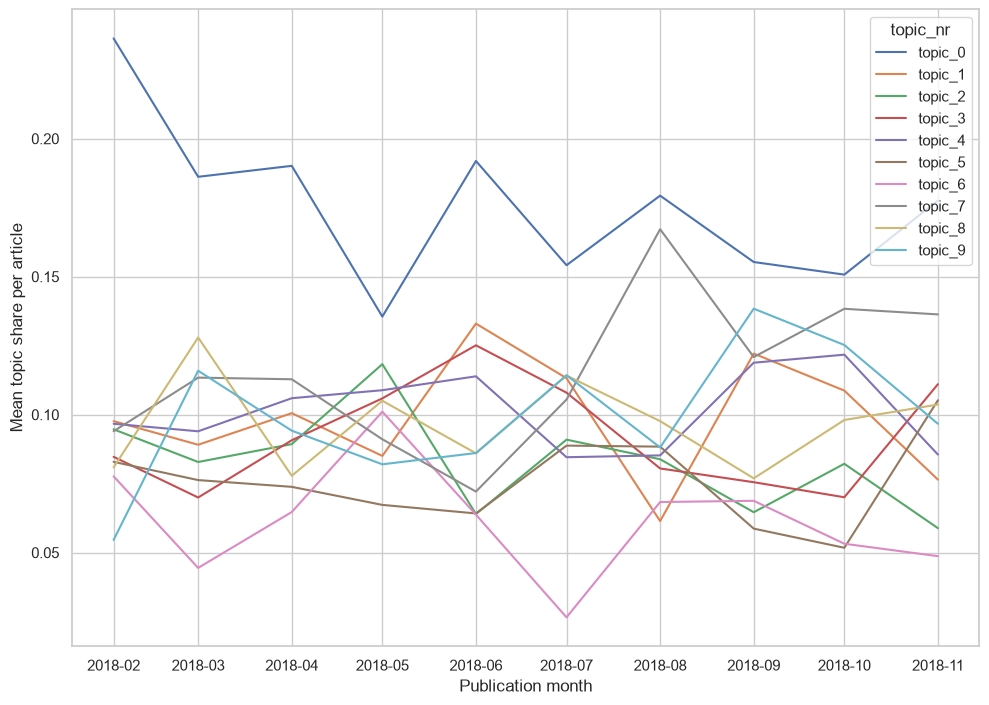

In [30]:
sns.set_theme(style="whitegrid", rc={"figure.figsize": (11.7, 8.27)})
ax = sns.lineplot(data=monthly, x="month", y="topic_score", hue="topic_nr", estimator=None)
ax.set(xlabel="Publication month", ylabel="Mean topic share per article")